In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as ms
import sklearn
from scipy import stats
import glob
%matplotlib inline

print('Done Setup')

Done Setup


In [66]:
from pathlib import Path

# Get one company ticker from each CSV filename in this folder
tickers = sorted(
    file.stem for file in Path('.').glob('*.csv')
    if file.stem != 'company_list'
)

# Save the ticker list as a CSV file
company_list = pd.DataFrame({'Company': tickers})
company_list.to_csv('company_list.csv', index=False)

print(f'Saved {len(tickers)} companies to company_list.csv')
company_list.head()

Saved 372 companies to company_list.csv


,Company
0,ACLBSL
1,ADBL
2,AHL
3,AHPC
4,AKJCL


# A = data Acquistion 

In [67]:
# Load every company CSV in the current folder
csv_files = sorted(
    file for file in Path('.').glob('*.csv')
    if file.stem != 'company_list'
)
tickers = [file.stem for file in csv_files]

dfs = []
for csv_file in csv_files:
    # Read the company's CSV file
    df = pd.read_csv(csv_file)

    # Add a column to identify the company
    df['Company'] = csv_file.stem

    # Ensure published_date is in datetime format
    df['published_date'] = pd.to_datetime(df['published_date'])

    dfs.append(df)

# Combine all company data into one DataFrame
nepse_data = pd.concat(dfs, ignore_index=True)

# Sort by date and company
nepse_data = nepse_data.sort_values(
    by=['published_date', 'Company']
).reset_index(drop=True)

print(f'Loaded {len(tickers)} company files')
nepse_data.head(10)

Loaded 372 company files


,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company
0,1995-07-20,2220.0,2220.0,2220.0,2220.0,0.0,560.0,0.0,0,BBC
1,1995-07-26,2220.0,2442.0,2442.0,2442.0,0.0,150.0,0.0,0,BBC
2,1995-07-30,2442.0,2500.0,2500.0,2500.0,0.0,200.0,0.0,0,BBC
3,1995-08-02,2500.0,2501.0,2501.0,2501.0,0.0,18.0,0.0,0,BBC
4,1995-08-06,2501.0,2500.0,2500.0,2500.0,0.0,40.0,0.0,0,BBC
5,1995-08-08,2500.0,2550.0,2550.0,2550.0,0.0,110.0,0.0,0,BBC
6,1995-08-20,2550.0,2600.0,2600.0,2600.0,0.0,23.0,0.0,0,BBC
7,1995-08-24,2600.0,2650.0,2650.0,2650.0,0.0,200.0,0.0,0,BBC
8,1995-09-11,2650.0,2815.0,2815.0,2815.0,0.0,36.0,0.0,0,BBC
9,1995-09-17,2815.0,3096.0,3096.0,3096.0,0.0,18.0,0.0,0,BBC


In [68]:
nepse_data.describe(include='all').T

/home/anuj/anaconda3/lib/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
published_date,516340,NaN,NaN,NaN,2021-10-05 07:18:47.787117,1995-07-20 00:00:00,2019-04-01 00:00:00,2022-10-11 00:00:00,2024-12-22 00:00:00,2026-10-16 00:00:00,NaN
open,516340.0,NaN,NaN,NaN,913.523811,0.0,254.0,471.1,847.0,55080.0,2422.779401
high,516340.0,NaN,NaN,NaN,928.165861,0.0,259.0,480.3,861.0,56805.8,2447.355912
low,516340.0,NaN,NaN,NaN,899.920989,0.0,249.0,463.0,833.0,53400.0,2398.222045
close,516340.0,NaN,NaN,NaN,913.682795,0.0,253.6,471.9,847.0,55000.0,2420.761658
per_change,516253.0,NaN,NaN,NaN,inf,-100.0,-1.23,0.0,1.05,inf,NaN
traded_quantity,516340.0,NaN,NaN,NaN,36138.532448,0.0,1809.0,8346.0,29936.0,11829714.0,107997.197841
traded_amount,516340.0,NaN,NaN,NaN,16054364.478652,0.0,694993.7,3863952.4,13523674.75,2012993143.0,43034332.430181
status,516340.0,NaN,NaN,NaN,-0.060946,-1.0,-1.0,0.0,1.0,1.0,0.873626
Company,516340,372,CHCL,4479,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
nepse_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 516340 entries, 0 to 516339
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   published_date   516340 non-null  datetime64[us]
 1   open             516340 non-null  float64       
 2   high             516340 non-null  float64       
 3   low              516340 non-null  float64       
 4   close            516340 non-null  float64       
 5   per_change       516253 non-null  float64       
 6   traded_quantity  516340 non-null  float64       
 7   traded_amount    516340 non-null  float64       
 8   status           516340 non-null  int64         
 9   Company          516340 non-null  str           
dtypes: datetime64[us](1), float64(7), int64(1), str(1)
memory usage: 41.5 MB


## null values

In [70]:
nepse_data.isna().sum()

published_date      0
open                0
high                0
low                 0
close               0
per_change         87
traded_quantity     0
traded_amount       0
status              0
Company             0
dtype: int64

### null valeues discription
- per_change = NaN, meaning the company has just started

### null graph

<Axes: >

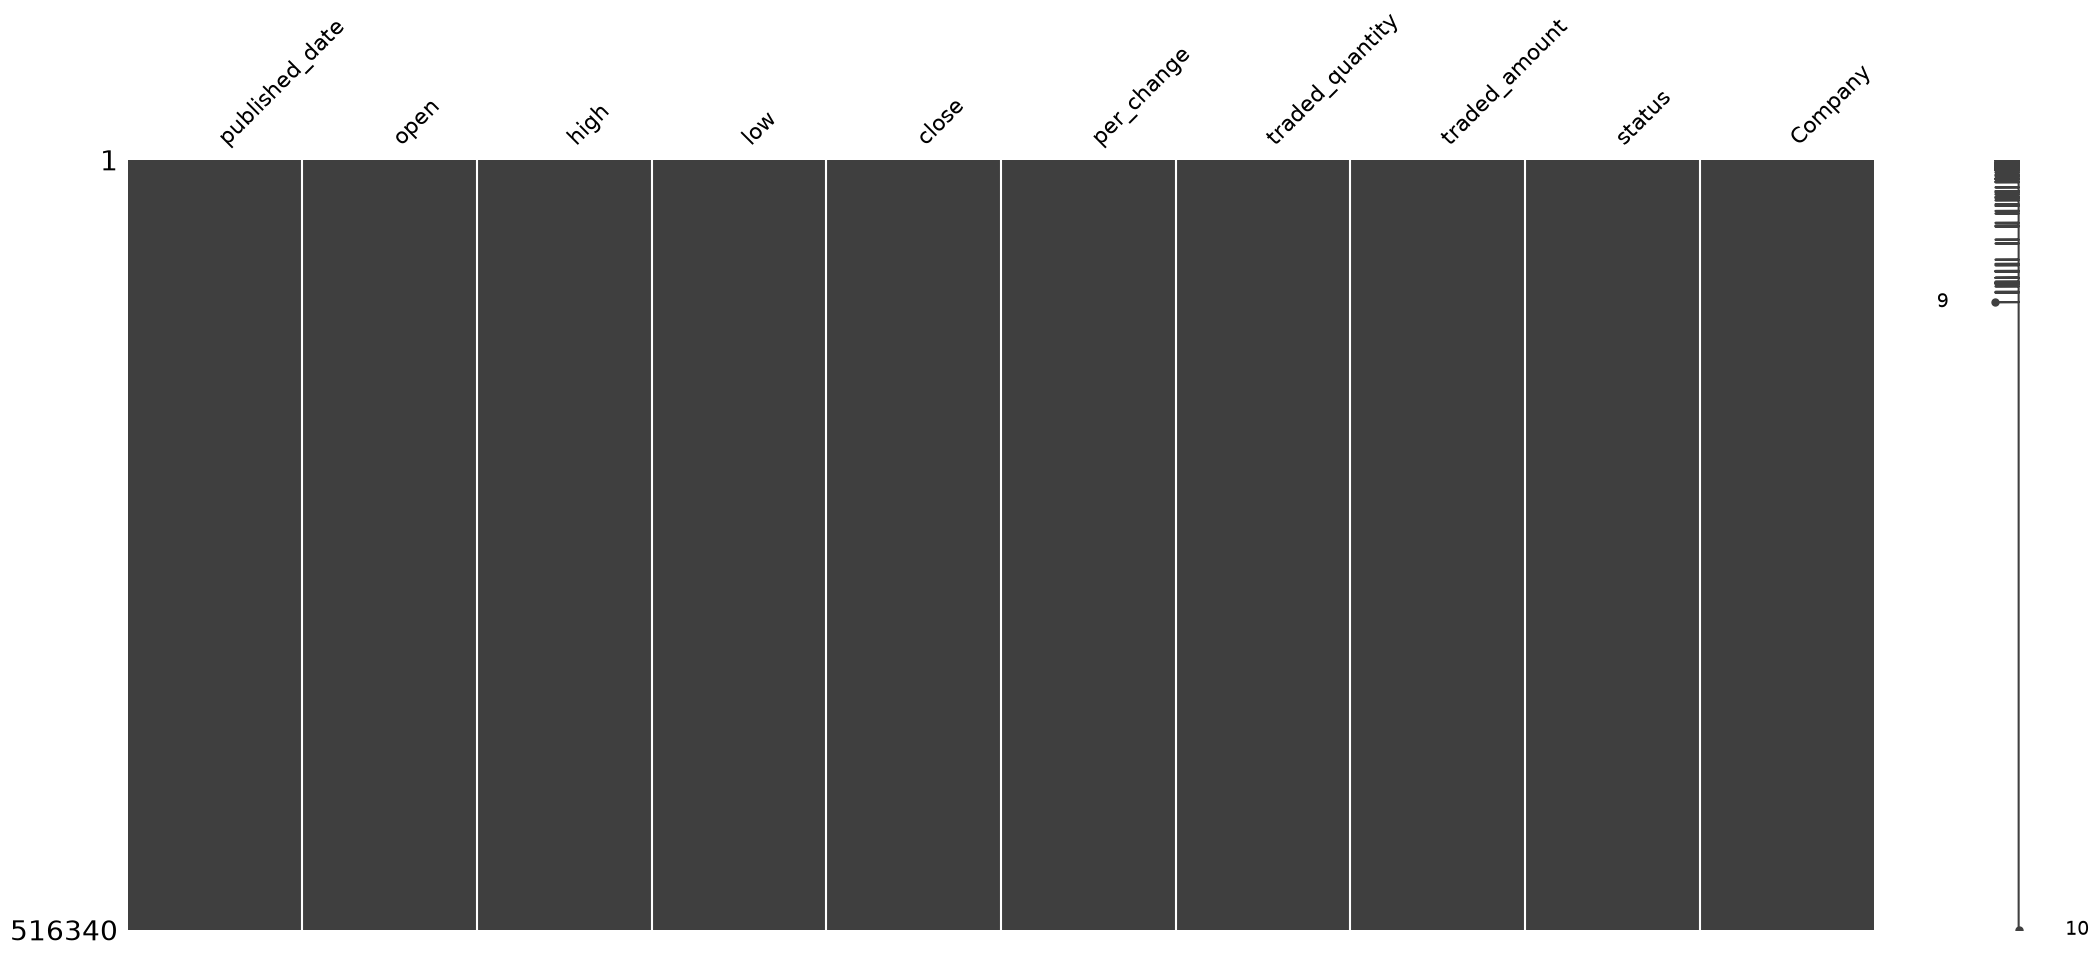

In [71]:
ms.matrix(nepse_data)

In [72]:
nepse_data.shape

(516340, 10)

# F = Data Filter

## company data fiter

In [73]:
nepse_data['Company'].value_counts()

Company
CHCL      4479
CZBIL     3929
BPCL      3779
AHPC      3779
ADBL      3679
          ... 
YMHL        79
SNORL       75
SLBBLP      50
CFL         41
CMB         14
Name: count, Length: 372, dtype: int64

### pie-chart

In [74]:
# # pie-chatt
# plt.figure(figsize = (10, 10))
# explode = [0.2,0.2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2]
# plt.pie(nepse_data['Company'].value_counts(), autopct='%1.2f%%', labels=tickers, explode= explode)
# plt.show()

### bar graphy traded amount

In [75]:
nepse_data.groupby('Company')['traded_amount'].sum()

Company
ACLBSL    6.418004e+09
ADBL      4.198486e+10
AHL       4.672642e+09
AHPC      1.092338e+11
AKJCL     6.392235e+10
              ...     
USLB      1.110676e+10
VLBS      7.924270e+09
VLUCL     8.523962e+09
WNLB      4.028817e+09
YMHL      1.185885e+09
Name: traded_amount, Length: 372, dtype: float64

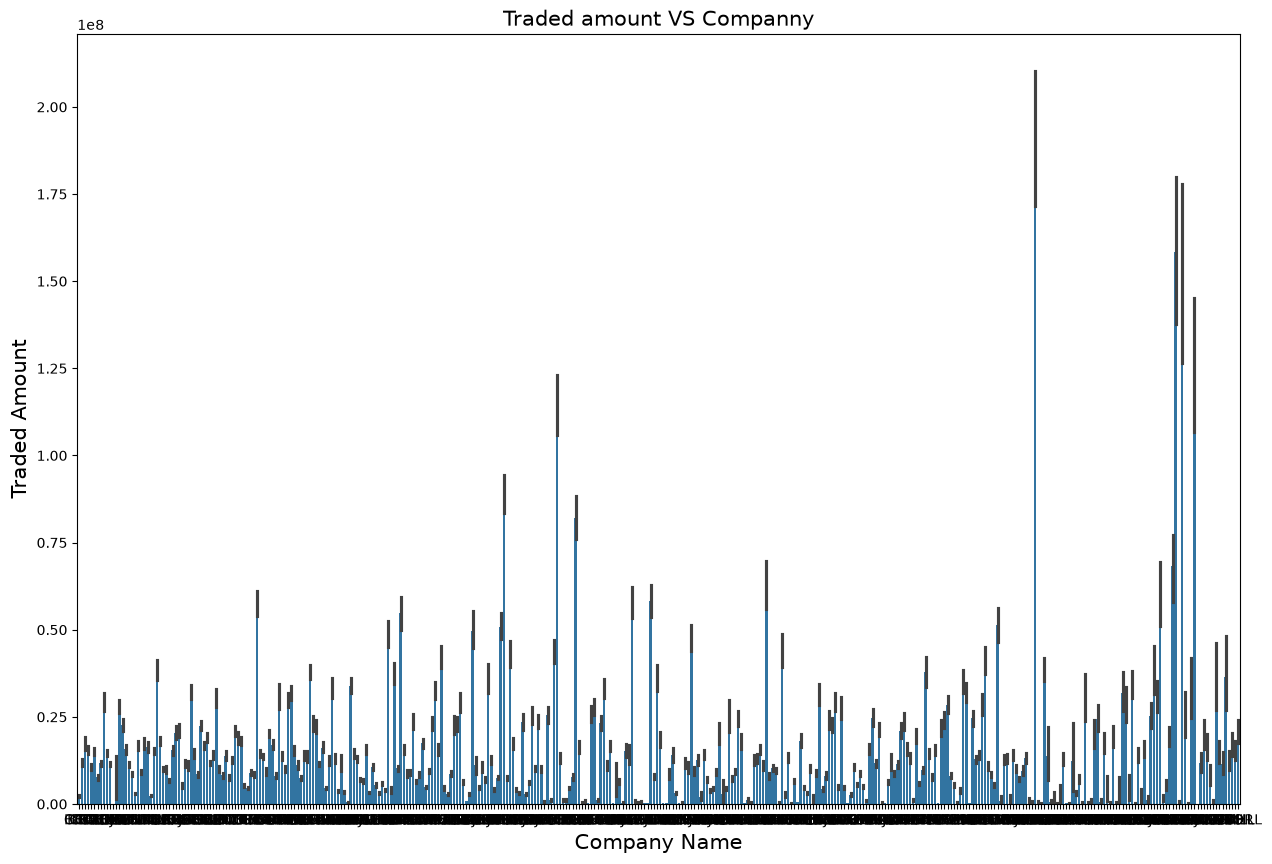

In [76]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_amount' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Amount', fontsize = 15)
plt.title('Traded amount VS Companny', fontsize = 15)
plt.show()

### bar graph for traded quantity

In [77]:
nepse_data.groupby('Company')['traded_quantity'].sum()

Company
ACLBSL      5528655.0
ADBL      104994539.0
AHL         8300458.0
AHPC      311907437.0
AKJCL     212714123.0
             ...     
USLB        6174930.0
VLBS        7496745.0
VLUCL      13860992.0
WNLB        1916340.0
YMHL        1979294.0
Name: traded_quantity, Length: 372, dtype: float64

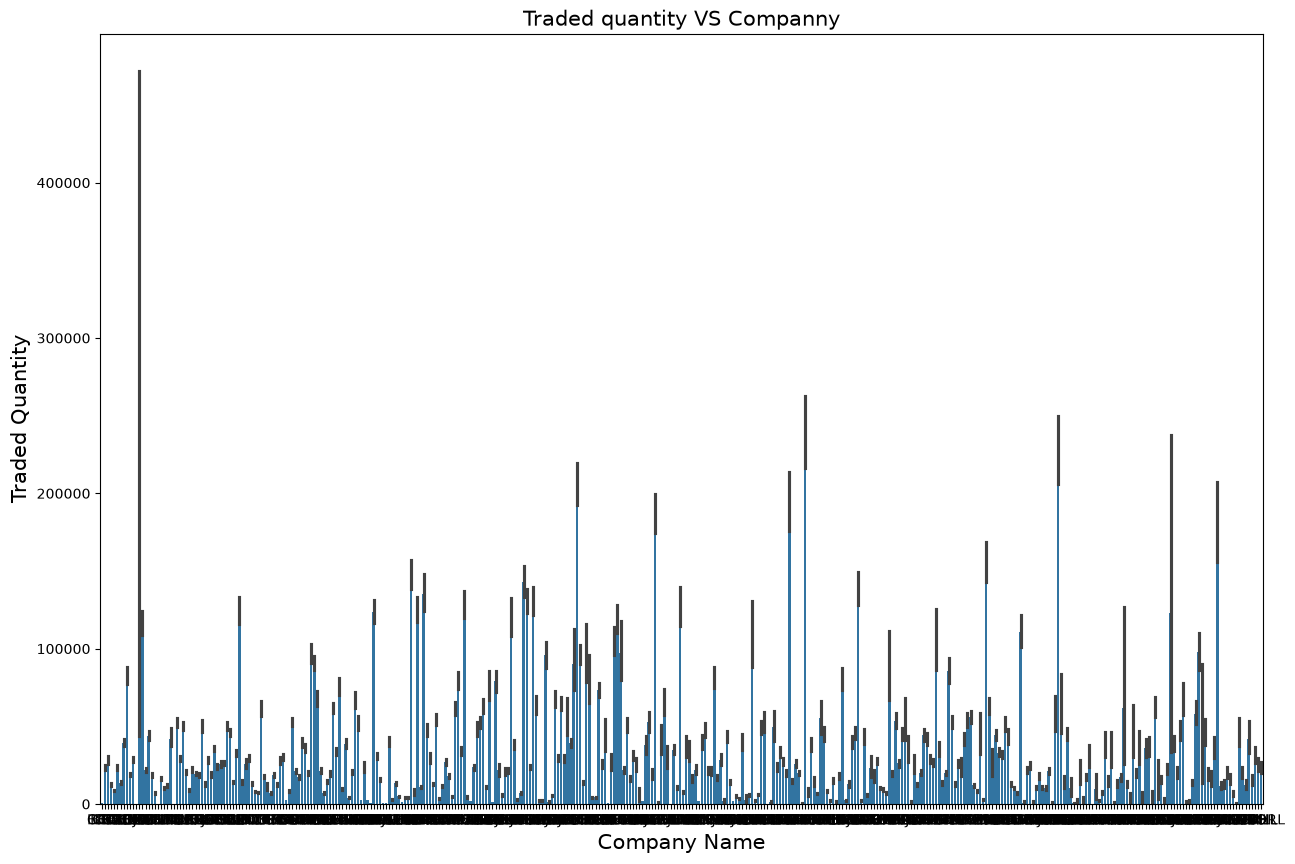

In [78]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_quantity' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Quantity', fontsize = 15)
plt.title('Traded quantity VS Companny', fontsize = 15)
plt.show()

## seperatiing published_date into year month and day


In [79]:
nepse_copy = nepse_data.copy()

nepse_copy['year'] = pd.to_datetime(nepse_copy['published_date']).dt.year
nepse_copy['month'] = pd.to_datetime(nepse_copy['published_date']).dt.month
nepse_copy['day'] = pd.to_datetime(nepse_copy['published_date']).dt.day

nepse_copy.head()

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,1995-07-20,2220.0,2220.0,2220.0,2220.0,0.0,560.0,0.0,0,BBC,1995,7,20
1,1995-07-26,2220.0,2442.0,2442.0,2442.0,0.0,150.0,0.0,0,BBC,1995,7,26
2,1995-07-30,2442.0,2500.0,2500.0,2500.0,0.0,200.0,0.0,0,BBC,1995,7,30
3,1995-08-02,2500.0,2501.0,2501.0,2501.0,0.0,18.0,0.0,0,BBC,1995,8,2
4,1995-08-06,2501.0,2500.0,2500.0,2500.0,0.0,40.0,0.0,0,BBC,1995,8,6


### droping column published_date from nepse_copy

In [80]:
nepse_copy.drop(columns = 'published_date', inplace= True)

## Time-Series analysis

### line-graph traded amount by year

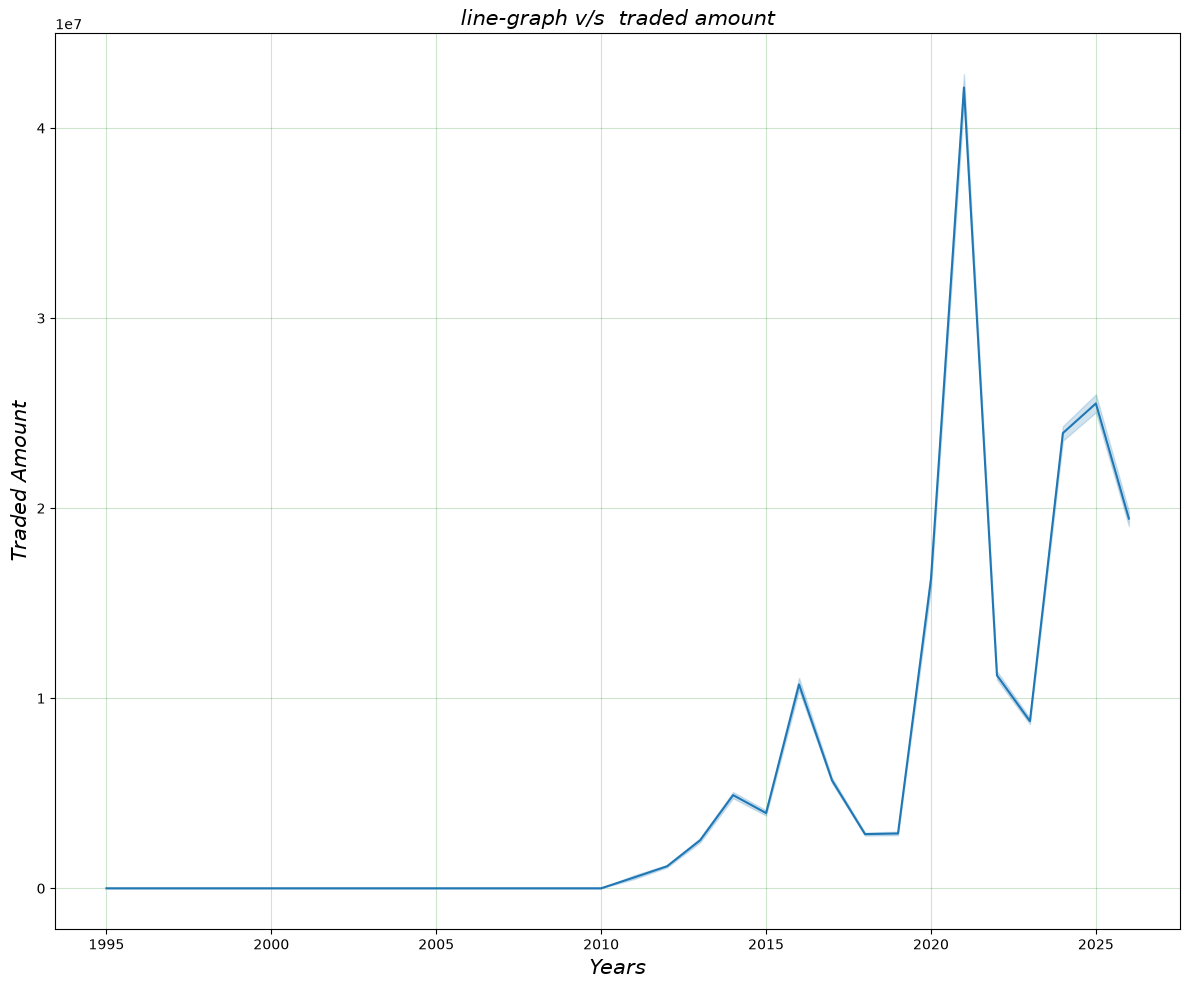

In [81]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_amount')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Amount', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded amount', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

### Line graph for traded quantity

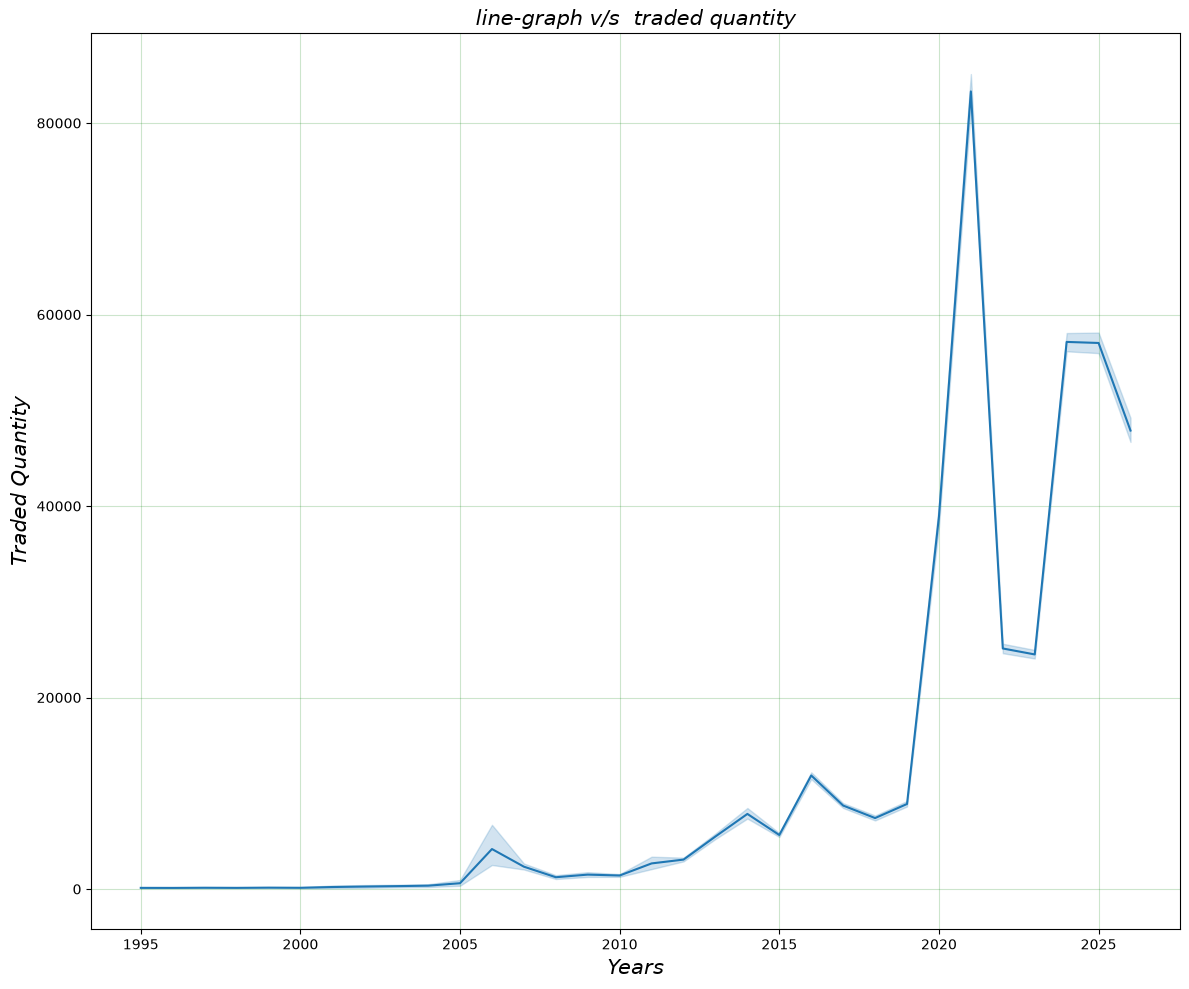

In [82]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_quantity')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

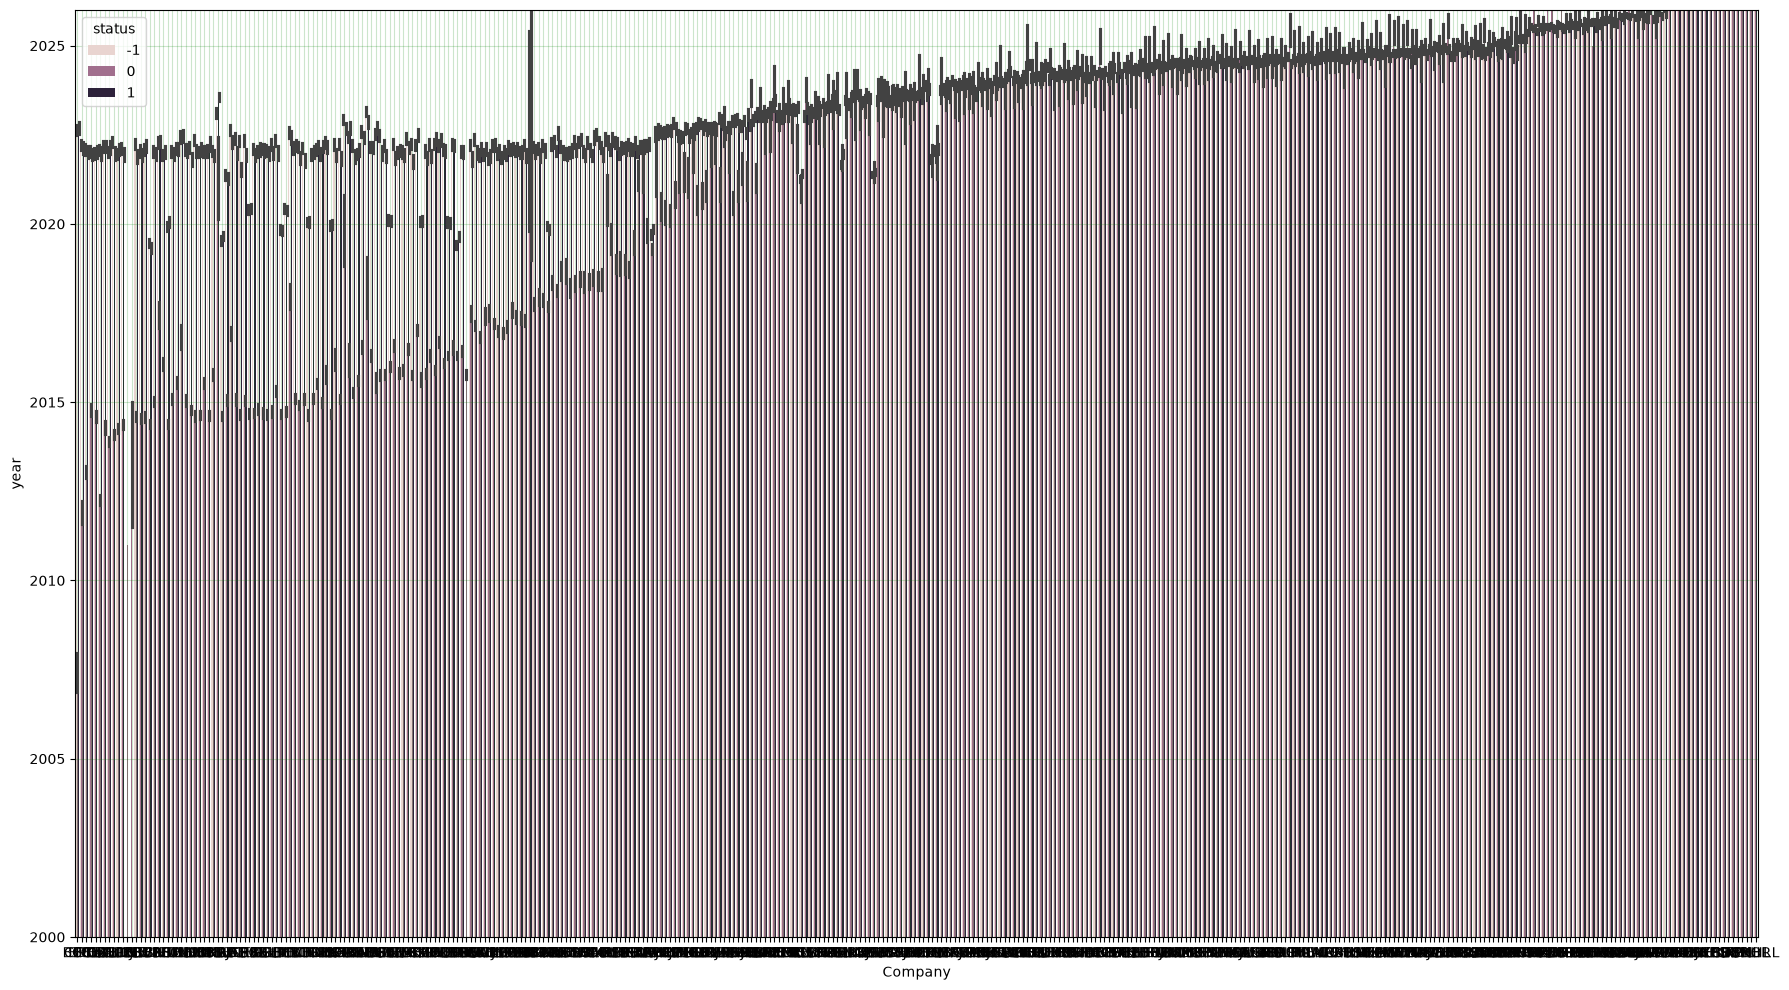

In [83]:
# status
plt.figure(figsize= (18, 10))
sns.barplot(data = nepse_copy, x = 'Company', y = 'year', hue = 'status')
plt.ylim((2000, 2026))
plt.grid(c = 'g', alpha = 0.2)
plt.margins(y = 0.1)
plt.tight_layout()
plt.show()


### Time series by Month

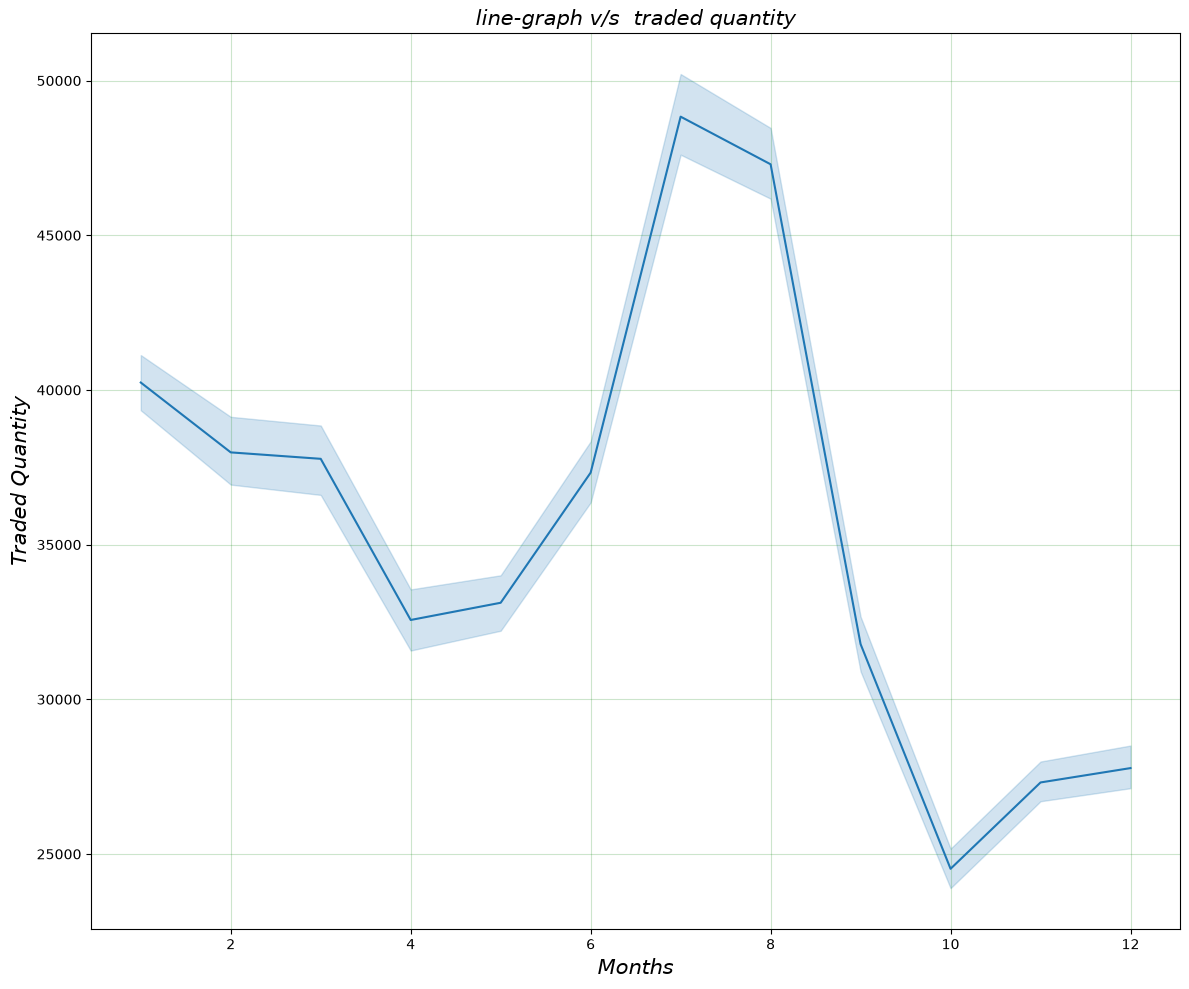

In [84]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'month', y = 'traded_quantity')
plt.xlabel('Months', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

## 2025 opening price

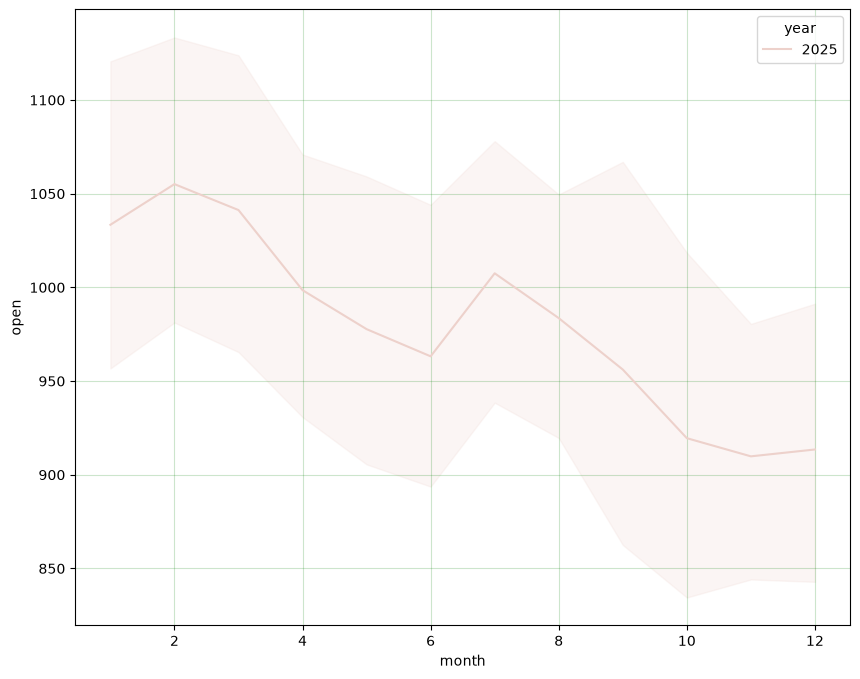

In [85]:
# 1. Filter the DataFrame first for the year 2025
plt.figure(figsize = (10, 8))
filtered_data = nepse_copy[nepse_copy['year'] == 2025]
sns.lineplot(data = filtered_data, x = 'month', y = 'open', hue = 'year')
plt.grid(c ='g', alpha = 0.2)
plt.show()

### 2026 opening vs 2025 opening amount

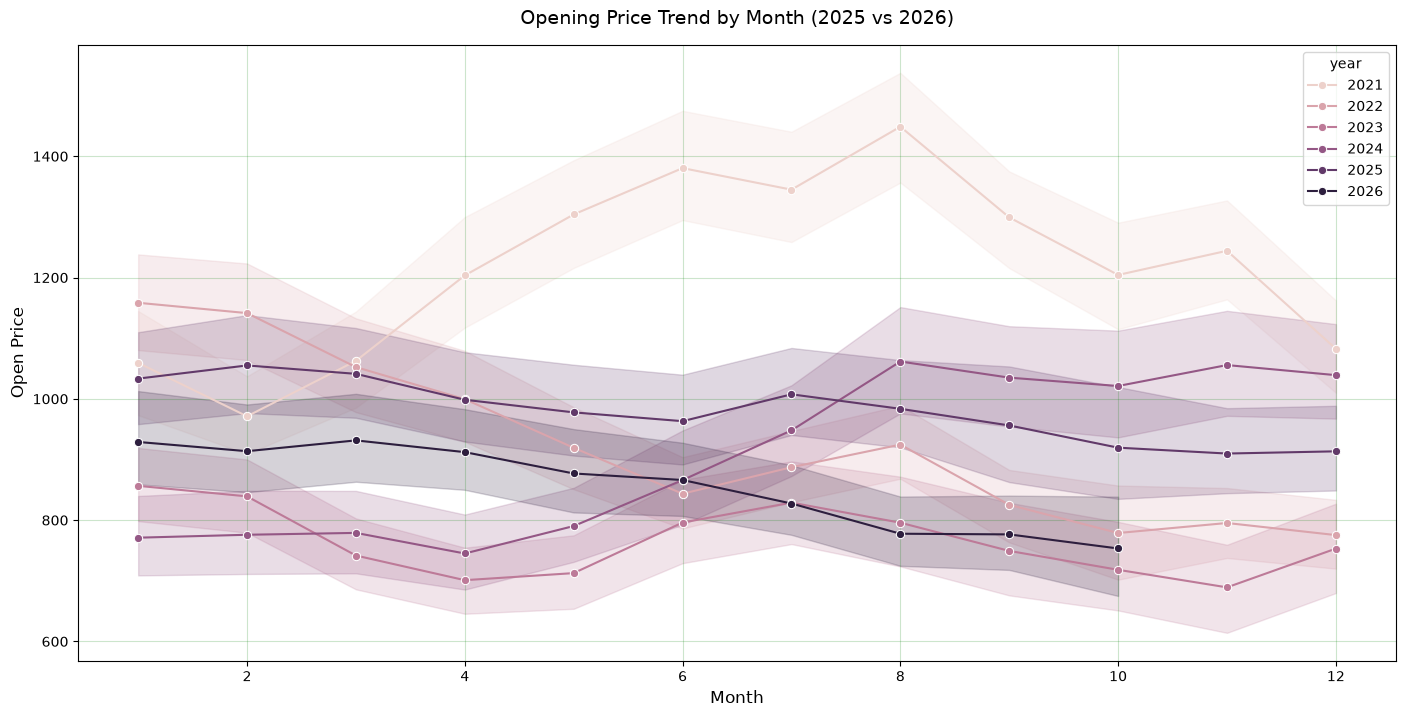

In [86]:

# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='open',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Opening Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Open Price', fontsize=12)

plt.show()

### closing analysis

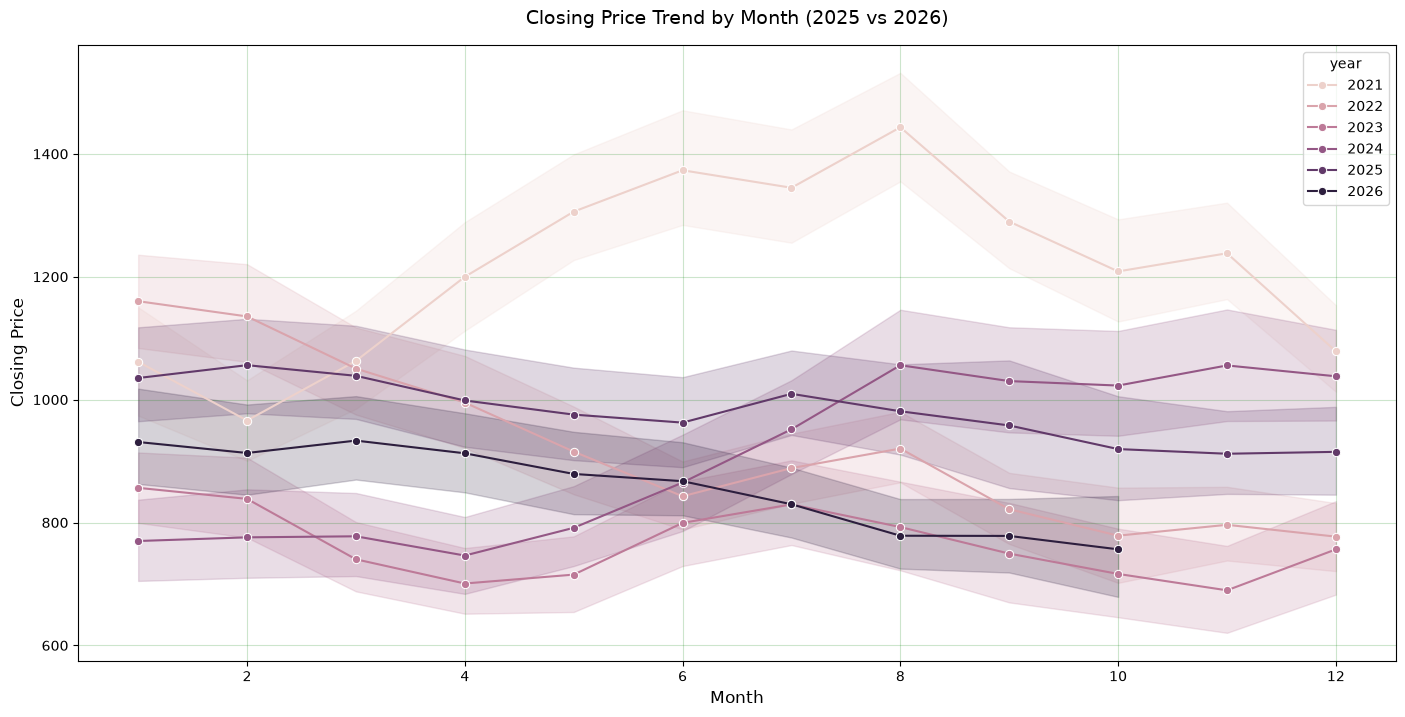

In [87]:
# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='close',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Closing Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Closing Price', fontsize=12)

plt.show()

# T = Transforming Data

## correlation


In [88]:
# correlation
nepse_data.corr(numeric_only=True)

,open,high,low,close,per_change,traded_quantity,traded_amount,status
open,1.000000,0.999794,0.999845,0.999723,-0.004356,-0.064827,-0.002678,0.001108
high,0.999794,1.000000,0.999711,0.999852,0.000385,-0.064490,-0.001111,0.003976
low,0.999845,0.999711,1.000000,0.999838,-0.001167,-0.065008,-0.003683,0.003208
close,0.999723,0.999852,0.999838,1.000000,0.003123,-0.064727,-0.002254,0.006080
per_change,-0.004356,0.000385,-0.001167,0.003123,1.000000,0.078736,0.090427,0.570446
traded_quantity,-0.064827,-0.064490,-0.065008,-0.064727,0.078736,1.000000,0.689728,0.035406
traded_amount,-0.002678,-0.001111,-0.003683,-0.002254,0.090427,0.689728,1.000000,0.039064
status,0.001108,0.003976,0.003208,0.006080,0.570446,0.035406,0.039064,1.000000


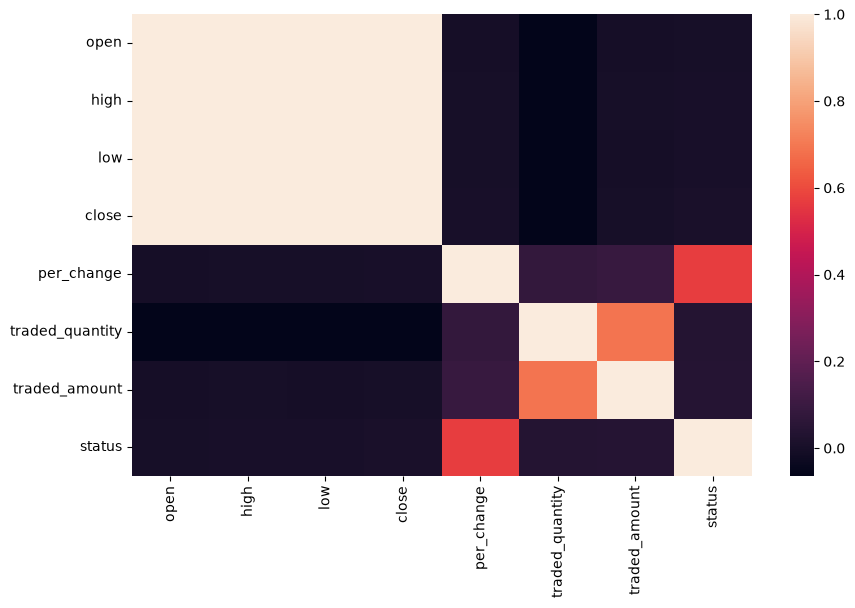

In [89]:
plt.figure(figsize=(10, 6))
sns.heatmap(nepse_data.corr(numeric_only=True))
plt.show()

## MACD INDICATOR column

In [90]:
# 1. Calculate the 12-period and 26-period EMAs of the Closing price
ema_12 = nepse_copy['close'].ewm(span=12, adjust=False).mean()
ema_26 = nepse_copy['close'].ewm(span=26, adjust=False).mean()

# 2. Compute the MACD Line
nepse_copy['macd'] = ema_12 - ema_26

# 3. Compute the Signal Line (9-period EMA of the MACD Line)
nepse_copy['macd_signal'] = nepse_copy['macd'].ewm(span=9, adjust=False).mean()

# 4. Compute the Histogram
nepse_copy['macd_histogram'] = nepse_copy['macd'] - nepse_copy['macd_signal']

### amount strength multiplier

In [91]:
# 1. Calculate the 20-day moving average of traded amount
nepse_copy['amount_sma20'] = nepse_copy['traded_amount'].rolling(window=20).mean()

# 2. Calculate Turnover Strength Multiplier
nepse_copy['strength_multiplier'] = nepse_copy['traded_amount'] / nepse_copy['amount_sma20']

In [92]:
nepse_copy

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day,macd,macd_signal,macd_histogram,amount_sma20,strength_multiplier
0,2220.0,2220.0,2220.0,2220.0,0.00,560.0,0.0,0,BBC,1995,7,20,0.000000,0.000000,0.000000,NaN,NaN
1,2220.0,2442.0,2442.0,2442.0,0.00,150.0,0.0,0,BBC,1995,7,26,17.709402,3.541880,14.167521,NaN,NaN
2,2442.0,2500.0,2500.0,2500.0,0.00,200.0,0.0,0,BBC,1995,7,30,36.009253,10.035355,25.973898,NaN,NaN
3,2500.0,2501.0,2501.0,2501.0,0.00,18.0,0.0,0,BBC,1995,8,2,50.016154,18.031515,31.984639,NaN,NaN
4,2501.0,2500.0,2500.0,2500.0,0.00,40.0,0.0,0,BBC,1995,8,6,60.340465,26.493305,33.847160,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516335,501.2,514.5,501.2,514.5,1.68,354.0,178119.7,1,USHL,2026,10,16,-86.733492,-51.714502,-35.018989,1.257913e+07,0.014160
516336,1050.0,1050.0,1025.0,1026.0,-1.36,788.0,810162.6,-1,USLB,2026,10,16,-45.920225,-50.555647,4.635422,1.048251e+07,0.077287
516337,602.0,614.0,602.0,610.5,0.41,2344.0,1432136.0,1,VLBS,2026,10,16,-46.566011,-49.757720,3.191709,4.223440e+06,0.339092
516338,366.1,371.0,363.0,369.0,-0.24,8974.0,3278052.9,1,VLUCL,2026,10,16,-65.806260,-52.967428,-12.838832,3.922211e+06,0.835767


In [93]:
nepse_copy.isna().sum()

open                      0
high                      0
low                       0
close                     0
per_change               87
traded_quantity           0
traded_amount             0
status                    0
Company                   0
year                      0
month                     0
day                       0
macd                      0
macd_signal               0
macd_histogram            0
amount_sma20             19
strength_multiplier    3701
dtype: int64

In [94]:


# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()

# Drop duplicate rows for the same company on the same date (keeps the last entry)
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
portfolio_values = growth_pivot * initial_capital_per_stock
total_portfolio_value = portfolio_values.sum(axis=1)

# Results
start_value = total_portfolio_value.iloc[0]
final_value = total_portfolio_value.iloc[-1]

print(f"Initial Portfolio Investment (2015): NPR {start_value:,.2f}")
print(f"Predicted Portfolio Value (2026): NPR {final_value:,.2f}")
print(f"Total Return Multiplier: {final_value / start_value:.2f}x")

Initial Portfolio Investment (2015): NPR 200,000.00
Predicted Portfolio Value (2026): NPR 715,882.88
Total Return Multiplier: 3.58x


In [95]:
import pandas as pd
import numpy as np

# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies and clean duplicates
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
company_portfolio_values = growth_pivot * initial_capital_per_stock

# --- INDIVIDUAL COMPANY PERFORMANCE REPORT ---
summary_list = []
for company in growth_pivot.columns:
    comp_series = company_portfolio_values[company].dropna()
    if len(comp_series) > 0:
        start_val = comp_series.iloc[0]
        final_val = comp_series.iloc[-1]
        multiplier = final_val / start_val if start_val > 0 else 1.0
        summary_list.append({
            'Company': company,
            'Initial (NPR)': start_val,
            'Predicted 2026 (NPR)': final_val,
            'Multiplier': multiplier
        })

summary_df = pd.DataFrame(summary_list)
print("--- Per-Company Backtest Performance Report (2015 - 2026) ---")
print(summary_df.to_string(index=False))
print("\n" + "="*60 + "\n")

# --- COMBINED PORTFOLIO SUMMARY ---
total_portfolio_value = company_portfolio_values.sum(axis=1)
total_start = total_portfolio_value.iloc[0]
total_final = total_portfolio_value.iloc[-1]

print(f"Total Initial Portfolio Investment (2015): NPR {total_start:,.2f}")
print(f"Total Predicted Portfolio Value (2026): NPR {total_final:,.2f}")
print(f"Overall Portfolio Return Multiplier: {total_final / total_start:.2f}x")

--- Per-Company Backtest Performance Report (2015 - 2026) ---
 Company  Initial (NPR)  Predicted 2026 (NPR)  Multiplier
  ACLBSL        10000.0          43529.564244    4.352956
    ADBL        10000.0          19080.520921    1.908052
     AHL        10000.0          11057.933642    1.105793
    AHPC        10000.0          72652.387851    7.265239
   AKJCL        10000.0          55079.337471    5.507934
    AKPL        10000.0          41069.973370    4.106997
   ALBSL        10000.0          20339.089887    2.033909
   ALICL        10000.0          53424.870542    5.342487
    ANLB        10000.0          25946.215590    2.594622
    APHL        10000.0          16097.312269    1.609731
     API        10000.0          59243.902446    5.924390
   AVYAN        10000.0          13217.635235    1.321764
BANDIPUR        10000.0          22426.922448    2.242692
   BARUN        10000.0         146624.124641   14.662412
     BBC        10000.0          40175.512164    4.017551
    BEDC  

# buy | sell through macd indicator

## loop buy sell

### Final 

In [ ]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Tax / Pure Fees)
def calculate_buy_cost(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    total_cost = gross + broker_comm + sebon_fee + dp_fee
    fees = broker_comm + sebon_fee + dp_fee
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    net_proceeds = gross - (broker_comm + sebon_fee + dp_fee)
    fees = broker_comm + sebon_fee + dp_fee
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
total_fees_accumulated = 0.0
completed_transactions = []
active_trades = []

# Simulation date range strictly starting from 2015-01-01
simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")
top_companies = nepse_copy['Company'].unique()

# Pre-scan potential trades where buy_date >= '2015-01-01'
all_potential_trades = []
for comp in top_companies:
    group = nepse_copy[nepse_copy['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    buys = group[(group['signal'] == 1) & (group['temp_date'] >= '2015-01-01')].reset_index(drop=True)
    
    for _, b_row in buys.iterrows():
        b_date = b_row['temp_date']
        b_rate = float(b_row['close'])
        b_macd = round(float(b_row['macd']), 4)
        
        future_group = group[group['temp_date'] > b_date].reset_index(drop=True)
        if len(future_group) == 0:
            continue
            
        best_sell = future_group.sort_values(by=['close', 'macd'], ascending=[False, False]).iloc[0]
        s_date = best_sell['temp_date']
        s_rate = float(best_sell['close'])
        s_macd = round(float(best_sell['macd']), 4)
        
        if s_rate > b_rate:
            all_potential_trades.append({
                'Company': comp,
                'buy_date': b_date,
                'buy_rate': b_rate,
                'macd_on_buyDate': b_macd,
                'sell_date': s_date,
                'sell_rate': s_rate,
                'macd_on_sellingDate': s_macd
            })

df_pot = pd.DataFrame(all_potential_trades)
if len(df_pot) > 0:
    df_pot = df_pot.sort_values(by=['buy_date', 'macd_on_buyDate'], ascending=[True, False]).reset_index(drop=True)

# Timeline loop starting from 2015-01-01
for curr_date in simulation_dates:
    still_active = []
    for tr in active_trades:
        if tr['sell_date_dt'] <= curr_date:
            cash_balance += tr['total_amount_recieved']
            total_fees_accumulated += tr['sell_fees']
            completed_transactions.append({
                'Company': tr['Company'],
                'buy_date': tr['buy_date'],
                'buy_quantity': tr['buy_quantity'],
                'buy_rate': tr['buy_rate'],
                'macd_on_buyDate': tr['macd_on_buyDate'],
                'Total_amount_buyCost': tr['Total_amount_buyCost'],
                'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
                'sell_quantity': tr['buy_quantity'],
                'sell_rate': tr['sell_rate'],
                'macd_on_sellingDate': tr['macd_on_sellingDate'],
                'total_amount_recieved': tr['total_amount_recieved'],
                'profit/loss': tr['pnl'],
                'profit/loss percentage respect to buy': tr['pnl_pct']
            })
        else:
            still_active.append(tr)
    active_trades = still_active

    if cash_balance > MIN_QUANTITY * 20:
        candidates_today = df_pot[df_pot['buy_date'] == curr_date]
        for _, cand in candidates_today.iterrows():
            b_rate = cand['buy_rate']
            min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_rate)
            
            if cash_balance >= min_buy_cost:
                max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                raw_qty = int((max_spend - 25) // (b_rate * 1.004))
                buy_qty = max(MIN_QUANTITY, raw_qty)
                
                buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                    buy_qty -= 1
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                    
                if buy_cost <= cash_balance:
                    cash_balance -= buy_cost
                    total_fees_accumulated += buy_fees
                    
                    s_rate = cand['sell_rate']
                    sell_proceeds, sell_fees = calculate_sell_proceeds(buy_qty, s_rate)
                    pnl = round(sell_proceeds - buy_cost, 2)
                    pnl_pct = round((pnl / buy_cost) * 100, 2)
                    
                    active_trades.append({
                        'Company': cand['Company'],
                        'buy_date': cand['buy_date'].strftime('%Y-%m-%d'),
                        'buy_quantity': buy_qty,
                        'buy_rate': b_rate,
                        'macd_on_buyDate': cand['macd_on_buyDate'],
                        'Total_amount_buyCost': buy_cost,
                        'sell_date_dt': cand['sell_date'],
                        'sell_rate': s_rate,
                        'macd_on_sellingDate': cand['macd_on_sellingDate'],
                        'total_amount_recieved': sell_proceeds,
                        'sell_fees': sell_fees,
                        'pnl': pnl,
                        'pnl_pct': pnl_pct
                    })
                    break

# Close remaining active trades at final date
for tr in active_trades:
    cash_balance += tr['total_amount_recieved']
    total_fees_accumulated += tr['sell_fees']
    completed_transactions.append({
        'Company': tr['Company'],
        'buy_date': tr['buy_date'],
        'buy_quantity': tr['buy_quantity'],
        'buy_rate': tr['buy_rate'],
        'macd_on_buyDate': tr['macd_on_buyDate'],
        'Total_amount_buyCost': tr['Total_amount_buyCost'],
        'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
        'sell_quantity': tr['buy_quantity'],
        'sell_rate': tr['sell_rate'],
        'macd_on_sellingDate': tr['macd_on_sellingDate'],
        'total_amount_recieved': tr['total_amount_recieved'],
        'profit/loss': tr['pnl'],
        'profit/loss percentage respect to buy': tr['pnl_pct']
    })

df_tx = pd.DataFrame(completed_transactions)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# Export to Excel Workbook ('Transactions' & 'Summary')
file_path = "NEPSE_Continuous_MACD_Compounding_Results.xlsx"
wb = openpyxl.Workbook()

ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws_tx.append(["NEPSE Continuous MACD Compounding Strategy - Transactions Log"])
ws_tx.append(["Initial Budget: NPR 200,000 | Initial Buys Strictly >= 2015-01-01 | Optimal Best-MACD Exit"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Continuous MACD Compounding Strategy - Executive Summary"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Total transaction costs", total_fees_accumulated, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of any unsold shares at the final historical price", 0.0, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to the initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30

wb.save(file_path)
# ==============================================================================
# 2. CREATE SECOND EXCEL FILE: Company Summary Excel File
# Structure: unique(company) | total_buy | total buy quantity | total sell quantity | total recieved amount
# ==============================================================================
comp_summary_file = "NEPSE_Company_Summary.xlsx"

if num_trades > 0:
    df_comp_summary = df_tx.groupby('Company').agg(
        total_buy=('Total_amount_buyCost', 'sum'),
        total_buy_quantity=('buy_quantity', 'sum'),
        total_sell_quantity=('sell_quantity', 'sum'),
        total_recieved_amount=('total_amount_recieved', 'sum')
    ).reset_index()
else:
    df_comp_summary = pd.DataFrame(columns=['Company', 'total_buy', 'total_buy_quantity', 'total_sell_quantity', 'total_recieved_amount'])

wb_comp = openpyxl.Workbook()
ws_comp = wb_comp.active
ws_comp.title = "Company Summary"
ws_comp.views.sheetView[0].showGridLines = True

ws_comp.append(["NEPSE Strategy - Per Company Aggregated Performance Summary"])
ws_comp.append(["Aggregated trading activity grouped by unique company symbol"])
ws_comp.append([])

ws_comp.cell(row=1, column=1).font = title_font
ws_comp.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_headers = ['Company', 'total_buy', 'total buy quantity', 'total sell quantity', 'total recieved amount']

ws_comp.append(comp_headers)
for col_num in range(1, len(comp_headers) + 1):
    cell = ws_comp.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_comp_summary.iterrows():
    row_values = [
        row['Company'],
        round(row['total_buy'], 2),
        int(row['total_buy_quantity']),
        int(row['total_sell_quantity']),
        round(row['total_recieved_amount'], 2)
    ]
    ws_comp.append(row_values)
    curr_row = 5 + r_idx
    
    # Format cells
    c_comp = ws_comp.cell(row=curr_row, column=1)
    c_buy = ws_comp.cell(row=curr_row, column=2)
    c_bqty = ws_comp.cell(row=curr_row, column=3)
    c_sqty = ws_comp.cell(row=curr_row, column=4)
    c_rec = ws_comp.cell(row=curr_row, column=5)
    
    for c in [c_comp, c_buy, c_bqty, c_sqty, c_rec]:
        c.border = thin_border
        
    c_comp.alignment = Alignment(horizontal="center")
    c_buy.number_format = 'NPR #,##0.00'
    c_buy.alignment = Alignment(horizontal="right")
    c_bqty.number_format = '#,##0'
    c_bqty.alignment = Alignment(horizontal="right")
    c_sqty.number_format = '#,##0'
    c_sqty.alignment = Alignment(horizontal="right")
    c_rec.number_format = 'NPR #,##0.00'
    c_rec.alignment = Alignment(horizontal="right")

ws_comp.row_dimensions[4].height = 28
for col in ws_comp.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp.column_dimensions[col_letter].width = max(max_len + 4, 18)

wb_comp.save(comp_summary_file)

In [ ]:
import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Create separate output folder
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Tax / Pure Fees)
def calculate_buy_cost(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    total_cost = gross + broker_comm + sebon_fee + dp_fee
    fees = broker_comm + sebon_fee + dp_fee
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    net_proceeds = gross - (broker_comm + sebon_fee + dp_fee)
    fees = broker_comm + sebon_fee + dp_fee
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
total_fees_accumulated = 0.0
completed_transactions = []
active_trades = []

# Simulation date range strictly starting from 2015-01-01
simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")
top_companies = nepse_copy['Company'].unique()

# Pre-scan potential trades where buy_date >= '2015-01-01'
all_potential_trades = []
for comp in top_companies:
    group = nepse_copy[nepse_copy['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    buys = group[(group['signal'] == 1) & (group['temp_date'] >= '2015-01-01')].reset_index(drop=True)
    
    for _, b_row in buys.iterrows():
        b_date = b_row['temp_date']
        b_rate = float(b_row['close'])
        b_macd = round(float(b_row['macd']), 4)
        
        future_group = group[group['temp_date'] > b_date].reset_index(drop=True)
        if len(future_group) == 0:
            continue
            
        best_sell = future_group.sort_values(by=['close', 'macd'], ascending=[False, False]).iloc[0]
        s_date = best_sell['temp_date']
        s_rate = float(best_sell['close'])
        s_macd = round(float(best_sell['macd']), 4)
        
        if s_rate > b_rate:
            all_potential_trades.append({
                'Company': comp,
                'buy_date': b_date,
                'buy_rate': b_rate,
                'macd_on_buyDate': b_macd,
                'sell_date': s_date,
                'sell_rate': s_rate,
                'macd_on_sellingDate': s_macd
            })

df_pot = pd.DataFrame(all_potential_trades)
if len(df_pot) > 0:
    df_pot = df_pot.drop_duplicates(subset=['Company', 'buy_date'])
    df_pot = df_pot.sort_values(by=['buy_date', 'macd_on_buyDate'], ascending=[True, False]).reset_index(drop=True)

# Timeline loop starting from 2015-01-01
for curr_date in simulation_dates:
    still_active = []
    for tr in active_trades:
        if tr['sell_date_dt'] <= curr_date:
            cash_balance += tr['total_amount_recieved']
            total_fees_accumulated += tr['sell_fees']
            completed_transactions.append({
                'Company': tr['Company'],
                'buy_date': tr['buy_date'],
                'buy_quantity': tr['buy_quantity'],
                'buy_rate': tr['buy_rate'],
                'macd_on_buyDate': tr['macd_on_buyDate'],
                'Total_amount_buyCost': tr['Total_amount_buyCost'],
                'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
                'sell_quantity': tr['buy_quantity'],
                'sell_rate': tr['sell_rate'],
                'macd_on_sellingDate': tr['macd_on_sellingDate'],
                'total_amount_recieved': tr['total_amount_recieved'],
                'profit/loss': tr['pnl'],
                'profit/loss percentage respect to buy': tr['pnl_pct']
            })
        else:
            still_active.append(tr)
    active_trades = still_active

    if cash_balance > MIN_QUANTITY * 20:
        candidates_today = df_pot[df_pot['buy_date'] == curr_date]
        for _, cand in candidates_today.iterrows():
            b_rate = cand['buy_rate']
            min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_rate)
            
            if cash_balance >= min_buy_cost:
                max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                raw_qty = int((max_spend - 25) // (b_rate * 1.004))
                buy_qty = max(MIN_QUANTITY, raw_qty)
                
                buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                    buy_qty -= 1
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                    
                if buy_cost <= cash_balance:
                    cash_balance -= buy_cost
                    total_fees_accumulated += buy_fees
                    
                    s_rate = cand['sell_rate']
                    sell_proceeds, sell_fees = calculate_sell_proceeds(buy_qty, s_rate)
                    pnl = round(sell_proceeds - buy_cost, 2)
                    pnl_pct = round((pnl / buy_cost) * 100, 2)
                    
                    active_trades.append({
                        'Company': cand['Company'],
                        'buy_date': cand['buy_date'].strftime('%Y-%m-%d'),
                        'buy_quantity': buy_qty,
                        'buy_rate': b_rate,
                        'macd_on_buyDate': cand['macd_on_buyDate'],
                        'Total_amount_buyCost': buy_cost,
                        'sell_date_dt': cand['sell_date'],
                        'sell_rate': s_rate,
                        'macd_on_sellingDate': cand['macd_on_sellingDate'],
                        'total_amount_recieved': sell_proceeds,
                        'sell_fees': sell_fees,
                        'pnl': pnl,
                        'pnl_pct': pnl_pct
                    })
                    break

# Close remaining active trades at final date
for tr in active_trades:
    cash_balance += tr['total_amount_recieved']
    total_fees_accumulated += tr['sell_fees']
    completed_transactions.append({
        'Company': tr['Company'],
        'buy_date': tr['buy_date'],
        'buy_quantity': tr['buy_quantity'],
        'buy_rate': tr['buy_rate'],
        'macd_on_buyDate': tr['macd_on_buyDate'],
        'Total_amount_buyCost': tr['Total_amount_buyCost'],
        'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
        'sell_quantity': tr['buy_quantity'],
        'sell_rate': tr['sell_rate'],
        'macd_on_sellingDate': tr['macd_on_sellingDate'],
        'total_amount_recieved': tr['total_amount_recieved'],
        'profit/loss': tr['pnl'],
        'profit/loss percentage respect to buy': tr['pnl_pct']
    })

df_tx = pd.DataFrame(completed_transactions)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# ==============================================================================
# 1. SAVE MAIN EXCEL WORKBOOK IN FOLDER
# ==============================================================================
file_path = os.path.join(output_dir, "NEPSE_Continuous_MACD_Compounding_Results.xlsx")
wb = openpyxl.Workbook()

ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws_tx.append(["NEPSE Continuous MACD Compounding Strategy - Transactions Log"])
ws_tx.append

<bound method Worksheet.append of <Worksheet "Transactions">>